In [135]:
# Core data manipulation and mathematical analysis
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning utilities: train/test dataset partitioning
from sklearn.model_selection import train_test_split


In [44]:
# Display all DataFrame columns without truncation in notebook outputs
pd.set_option('display.max_columns', None)

# Central constant defining the continuous target variable name for regression
TARGET_COL = "Customer Lifetime Value"


In [45]:
# Load the raw auto insurance customer records from CSV
df = pd.read_csv("auto_insurance.csv")


In [46]:
# Inspect the first 5 records to verify feature schema and sample values
df.head()


,Customer,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size
0,BU79786,Washington,2763.519279,No,Basic,Bachelor,2/24/11,Employed,F,56274,Suburban,Married,69,32,5,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize
1,QZ44356,Arizona,6979.535903,No,Extended,Bachelor,1/31/11,Unemployed,F,0,Suburban,Single,94,13,42,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize
2,AI49188,Nevada,12887.431650,No,Premium,Bachelor,2/19/11,Employed,F,48767,Suburban,Married,108,18,38,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize
3,WW63253,California,7645.861827,No,Basic,Bachelor,1/20/11,Unemployed,M,0,Suburban,Married,106,18,65,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize
4,HB64268,Washington,2813.692575,No,Basic,Bachelor,3/2/2011,Employed,M,43836,Rural,Single,73,12,44,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize


In [47]:
# Display total dataset dimensions (rows, columns)
print(f"Shape :
 {df.shape}")
print("-" * 141)

# List all attribute names in the dataset
print(f"Columns :
 {df.columns.to_list()}")
print("-" * 141)

# Inspect inferred data types across all features
print(f"types :
 {df.dtypes}")
print("-" * 141)

# Count missing / null values per attribute (0 indicates 100% complete)
print(f"Missing values :
 {df.isna().sum()}")
print("-" * 141)

# Check for exact duplicate rows across all columns including Customer ID
print(f"duplicate : {df.duplicated().sum()}")
print("-" * 141)

# Inspect unique value cardinality per column
print(f"nunique : {df.nunique()}")


Shape :
 (9134, 24)
---------------------------------------------------------------------------------------------------------------------------------------------
Columns :
 ['Customer', 'State', 'Customer Lifetime Value', 'Response', 'Coverage', 'Education', 'Effective To Date', 'EmploymentStatus', 'Gender', 'Income', 'Location Code', 'Marital Status', 'Monthly Premium Auto', 'Months Since Last Claim', 'Months Since Policy Inception', 'Number of Open Complaints', 'Number of Policies', 'Policy Type', 'Policy', 'Renew Offer Type', 'Sales Channel', 'Total Claim Amount', 'Vehicle Class', 'Vehicle Size']
---------------------------------------------------------------------------------------------------------------------------------------------
types :
 Customer                          object
State                             object
Customer Lifetime Value          float64
Response                          object
Coverage                          object
Education                         obj

In [48]:
# Statistical summary of the target variable (count, mean, std, quartiles, min, max)
df[TARGET_COL].describe()


count     9134.000000
mean      8004.940475
std       6870.967608
min       1898.007675
25%       3994.251794
50%       5780.182197
75%       8962.167041
max      83325.381190
Name: Customer Lifetime Value, dtype: float64

In [49]:
# Count customers reporting an Income of exactly zero
print(f"Income == 0 : {(df["Income"] == 0).sum()}")


Income == 0 : 2317


In [50]:
# Cross-tabulate EmploymentStatus against zero-income records
# Confirms that all zero-income records correspond to Unemployed status (valid domain values)
pd.crosstab(df["EmploymentStatus"], df["Income"] == 0)


Income,False,True
EmploymentStatus,,
Disabled,405,0
Employed,5698,0
Medical Leave,432,0
Retired,282,0
Unemployed,0,2317


In [51]:
# Evaluate income distribution specifically for employed policyholders (Income > 0)
df.loc[df["Income"] > 0, 'Income'].describe()


count     6817.000000
mean     50456.580461
std      24305.956566
min      10037.000000
25%      28432.000000
50%      48081.000000
75%      70187.000000
max      99981.000000
Name: Income, dtype: float64

In [52]:
# Attempt standard datetime conversion; "coerce" turns unparseable formats into NaT
parsed = pd.to_datetime(df["Effective To Date"], errors='coerce')


/var/folders/64/grj5pyf15ys44prkvy9xkwbr0000gn/T/ipykernel_29432/812662837.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(df["Effective To Date"], errors='coerce')


In [53]:
# Diagnose parsing failures from naive conversion attempt
print("Failed to parse:", parsed.isna().sum())
print("Min date:", parsed.min())
print("Max date:", parsed.max())
print("-" * 75)

# Inspect distribution of parsed dates across calendar months
print("Rows per month:")
print(parsed.dt.month.value_counts().sort_index())
print("-" * 75)

# Inspect sample unparsed date strings at the tail of the dataset to identify format anomalies
print(df.loc[[9129, 9130, 9131, 9132], "Effective To Date"])


Failed to parse: 0
Min date: 2011-01-01 00:00:00
Max date: 2011-12-02 00:00:00
---------------------------------------------------------------------------
Rows per month:
Effective To Date
1     3356
2     2722
3      336
4      279
5      325
6      287
7      308
8      283
9      283
10     356
11     317
12     282
Name: count, dtype: int64
---------------------------------------------------------------------------
9129    10/2/2011
9130    12/2/2011
9131     6/2/2011
9132     3/2/2011
Name: Effective To Date, dtype: object


In [54]:
# Extract the raw date string column for structural analysis
raw_date = df["Effective To Date"]

# Check length of the year component (split by "/" -> index 2) to identify 2-digit vs 4-digit years
year_len = raw_date.str.split("/").str[2].str.len()
print(year_len.value_counts())
print("-" * 75)

# Partition strings into short (2-digit year) and long (4-digit year) cohorts
short = raw_date[year_len == 2]
long = raw_date[year_len == 4]

# Verify date range for short strings using "%m/%d/%y" format
print("Short, m/d/y:",
      pd.to_datetime(short, format="%m/%d/%y").min(),
      pd.to_datetime(short, format="%m/%d/%y").max())
print("-" * 75)

# Test "%m/%d/%Y" on 4-digit year strings
long_md = pd.to_datetime(long, format="%m/%d/%Y")
print("Long, m/d/Y:", long_md.min(), long_md.max())
print("-" * 75)

# Test "%d/%m/%Y" on 4-digit year strings to identify the correct convention
long_dm = pd.to_datetime(long, format="%d/%m/%Y")
print("Long, d/m/Y:", long_dm.min(), long_dm.max())


Effective To Date
2    5467
4    3667
Name: count, dtype: int64
---------------------------------------------------------------------------
Short, m/d/y: 2011-01-13 00:00:00 2011-02-28 00:00:00
---------------------------------------------------------------------------
Long, m/d/Y: 2011-01-01 00:00:00 2011-12-02 00:00:00
---------------------------------------------------------------------------
Long, d/m/Y: 2011-01-01 00:00:00 2011-02-12 00:00:00


In [55]:
# Boolean mask identifying rows with 4-digit years
long_mask = year_len == 4

# Initialize the new parsed date column with NaT (missing datetime placeholder)
df["Effective To Date (parsed)"] = pd.NaT

# Parse 4-digit years using day-first convention ("%d/%m/%Y")
df.loc[long_mask, "Effective To Date (parsed)"] = pd.to_datetime(long, format="%d/%m/%Y")

# Parse 2-digit years using month-first convention ("%m/%d/%y")
df.loc[~long_mask, "Effective To Date (parsed)"] = pd.to_datetime(short, format="%m/%d/%y")


In [56]:
# Transposed descriptive statistics across all numerical attributes for easy scannability
df.describe().T


,count,mean,min,25%,50%,75%,max,std
Customer Lifetime Value,9134.0,8004.940475,1898.007675,3994.251794,5780.182197,8962.167041,83325.38119,6870.967608
Income,9134.0,37657.380009,0.0,0.0,33889.5,62320.0,99981.0,30379.904734
Monthly Premium Auto,9134.0,93.219291,61.0,68.0,83.0,109.0,298.0,34.407967
Months Since Last Claim,9134.0,15.097,0.0,6.0,14.0,23.0,35.0,10.073257
Months Since Policy Inception,9134.0,48.064594,0.0,24.0,48.0,71.0,99.0,27.905991
Number of Open Complaints,9134.0,0.384388,0.0,0.0,0.0,0.0,5.0,0.910384
Number of Policies,9134.0,2.96617,1.0,1.0,2.0,4.0,9.0,2.390182
Total Claim Amount,9134.0,434.088794,0.099007,272.258244,383.945434,547.514839,2893.239678,290.500092
Effective To Date (parsed),9134,2011-01-29 20:06:21.519597056,2011-01-01 00:00:00,2011-01-15 00:00:00,2011-01-29 00:00:00,2011-02-13 00:00:00,2011-02-28 00:00:00,NaN


In [58]:
col = "Effective To Date (parsed)"

# Confirm zero remaining unparsed dates (NaT values)
print("Rows still NaT:", df[col].isna().sum())

# Check minimum and maximum date boundaries across the entire dataset
print("Min:", df[col].min(), "| Max:", df[col].max())

# Check number of distinct calendar days in the observation window (Jan 1, 2011 - Feb 28, 2011)
print("Unique dates:", df[col].nunique())

# Verify total record count matches original dataset size
print("Rows:", len(df))


Rows still NaT: 0
Min: 2011-01-01 00:00:00 | Max: 2011-02-28 00:00:00
Unique dates: 59
Rows: 9134


In [60]:
# Record baseline observation count prior to deduplication
rows_before = len(df)
print(f"Rows Before : {rows_before}")

# Check exact duplicate rows when including synthetic unique identifier "Customer" (returns 0)
print("duplicates :", df.duplicated().sum())

# Drop synthetic primary key "Customer" to check for genuine duplicate policyholder profiles
df_noid = df.drop(columns=["Customer"])

# Count duplicate profiles revealed after excluding the synthetic ID
print("Duplicates AFTER dropping the ID :", df_noid.duplicated().sum())


Rows Before : 9134
duplicates : 0
Duplicates AFTER dropping the ID : 163


In [63]:
# Inspect sample duplicate records (showing all occurrences) sorted by CLV
df_noid[df_noid.duplicated(keep=False)].sort_values(by=TARGET_COL).head(10)


,State,Customer Lifetime Value,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size,Effective To Date (parsed)
7135,Oregon,2004.350666,Yes,Basic,College,2/22/11,Unemployed,F,0,Suburban,Divorced,66,16,35,4,1,Personal Auto,Personal L3,Offer1,Branch,316.800000,Four-Door Car,Small,2011-02-22
3665,Oregon,2004.350666,Yes,Basic,College,2/22/11,Unemployed,F,0,Suburban,Divorced,66,16,35,4,1,Personal Auto,Personal L3,Offer1,Branch,316.800000,Four-Door Car,Small,2011-02-22
4104,Oregon,2300.691547,Yes,Basic,Bachelor,1/15/11,Retired,M,25905,Suburban,Divorced,63,21,12,0,1,Personal Auto,Personal L3,Offer1,Agent,302.400000,Four-Door Car,Large,2011-01-15
4502,Oregon,2300.691547,Yes,Basic,Bachelor,1/15/11,Retired,M,25905,Suburban,Divorced,63,21,12,0,1,Personal Auto,Personal L3,Offer1,Agent,302.400000,Four-Door Car,Large,2011-01-15
5167,Nevada,2359.423599,Yes,Basic,Bachelor,11/1/2011,Disabled,F,19864,Suburban,Divorced,63,22,96,0,1,Personal Auto,Personal L3,Offer1,Web,352.394515,Four-Door Car,Medsize,2011-01-11
6414,Nevada,2359.423599,Yes,Basic,Bachelor,11/1/2011,Disabled,F,19864,Suburban,Divorced,63,22,96,0,1,Personal Auto,Personal L3,Offer1,Web,352.394515,Four-Door Car,Medsize,2011-01-11
5632,Oregon,2395.570000,Yes,Basic,Doctor,1/27/11,Disabled,F,21986,Suburban,Divorced,63,1,9,0,1,Personal Auto,Personal L3,Offer2,Branch,333.696228,Two-Door Car,Medsize,2011-01-27
4935,Oregon,2395.570000,Yes,Basic,Doctor,1/27/11,Disabled,F,21986,Suburban,Divorced,63,1,9,0,1,Personal Auto,Personal L3,Offer2,Branch,333.696228,Two-Door Car,Medsize,2011-01-27
1774,California,2396.219292,Yes,Basic,Bachelor,10/1/2011,Unemployed,F,0,Suburban,Married,66,6,71,2,1,Corporate Auto,Corporate L1,Offer2,Call Center,433.160284,Four-Door Car,Large,2011-01-10
6586,California,2396.219292,Yes,Basic,Bachelor,10/1/2011,Unemployed,F,0,Suburban,Married,66,6,71,2,1,Corporate Auto,Corporate L1,Offer2,Call Center,433.160284,Four-Door Car,Large,2011-01-10


In [65]:
# Purge duplicate policyholder records, keeping the first occurrence
df_clean = df_noid.drop_duplicates()

# Summarize deduplication results
print("Rows before:", rows_before)
print("Rows after:", len(df_clean))
print("Rows removed:", rows_before - len(df_clean))
print("Shape:", df_clean.shape)
print("Duplicates left:", df_clean.duplicated().sum())


Rows before: 9134
Rows after: 8971
Rows removed: 163
Shape: (8971, 24)
Duplicates left: 0


In [69]:
# Separate predictor feature matrix (X) and continuous target vector (y)
X = df_clean.drop(columns=[TARGET_COL])
y = df_clean[TARGET_COL]

# Perform 80/20 train/test split with fixed seed (42) for reproducible evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Verify partition dimensions (7,176 train / 1,795 test)
print("Shapes:")
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print("-" * 75)

# Verify absence of target variable in feature matrices to prevent data leakage
print("Target in X_train:", TARGET_COL in X_train.columns.to_list())
print("Target in X_test:", TARGET_COL in X_test.columns.to_list())
print("-" * 75)

# Compare target distributions between train and test splits to ensure no distribution shift
print("y_train :
", y_train.describe())
print("-" * 50)
print("y_test :
", y_test.describe())


Shapes:
(7176, 23)
(1795, 23)
(7176,)
(1795,)
---------------------------------------------------------------------------
False
False
---------------------------------------------------------------------------
y_train :
count     7176.000000
mean      8008.349211
std       6917.658715
min       1898.007675
25%       3985.490513
50%       5802.450724
75%       8984.682679
max      74228.516040
Name: Customer Lifetime Value, dtype: float64
--------------------------------------------------
y_test :
count     1795.000000
mean      7987.574014
std       6667.337637
min       2034.993043
25%       4022.239978
50%       5717.221919
75%       8900.944435
max      83325.381190
Name: Customer Lifetime Value, dtype: float64


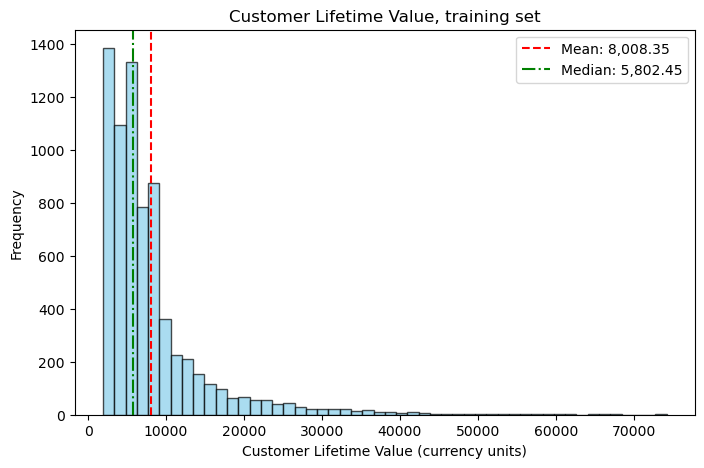

In [89]:
# Initialize canvas for target variable distribution analysis
plt.figure(figsize=(8, 5))

# Plot histogram of Customer Lifetime Value (training set) across 50 bins
# Use semi-transparency (alpha=0.7) and black edges for clear bin demarcation
plt.hist(y_train, bins=50, color='skyblue', edgecolor='black', alpha=0.7)

# Add clear chart annotations and axis labels with measurement units
plt.title("Customer Lifetime Value, training set")
plt.xlabel("Customer Lifetime Value (currency units)")
plt.ylabel("Frequency")

# Calculate parametric (mean) and non-parametric (median) central tendency metrics
mean_val = y_train.mean()
median_val = y_train.median()

# Overlay reference lines to visualize distribution asymmetry and skewness
# Mean > Median visually confirms a heavily right-skewed target distribution
plt.axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:,.2f}')
plt.axvline(median_val, color='green', linestyle='-.', linewidth=1.5, label=f'Median: {median_val:,.2f}')
plt.legend()

plt.show()


In [86]:
# Quantify central tendency and positive skewness of the target variable
# Skewness ~2.97 indicates strong right skew (heavy positive tail of high-value policyholders)
print("Mean:", y_train.mean(), "| Median:", y_train.median())
print("Skew:", y_train.skew())


Mean: 8008.349211184365 | Median: 5802.450724
Skew: 3.044898028387601


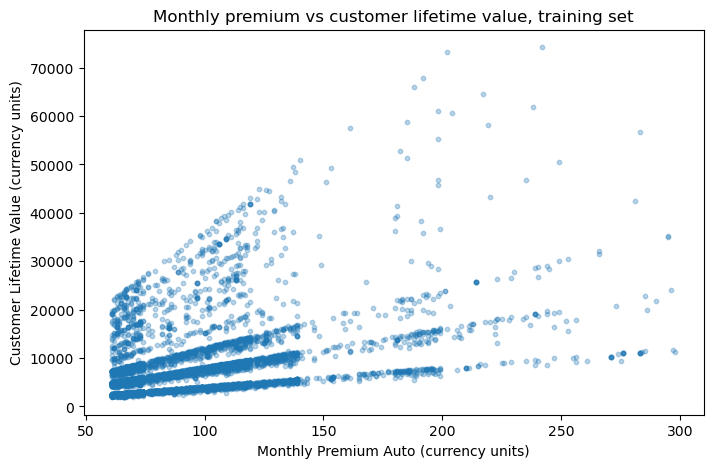

In [96]:
# Construct temporary training DataFrame combining features and target for bivariate EDA
train_df = X_train.copy()
train_df[TARGET_COL] = y_train

# Scatter plot: Monthly Premium Auto vs Customer Lifetime Value
# Low alpha (0.3) and small marker size (s=10) prevent visual saturation across 7,176 points
# Highlights distinct linear rays/stripes radiating from the origin
plt.figure(figsize=(8, 5))
plt.scatter(x='Monthly Premium Auto', y=TARGET_COL, data=train_df, alpha=0.3, s=10)
plt.title("Monthly premium vs customer lifetime value, training set")
plt.xlabel("Monthly Premium Auto (currency units)")
plt.ylabel("Customer Lifetime Value (currency units)")
plt.show()


In [93]:
# Calculate Pearson correlation coefficient between monthly premium and CLV
# Moderate positive correlation (~0.40) establishes Monthly Premium Auto as a key driver
print("Correlation:", train_df["Monthly Premium Auto"].corr(train_df[TARGET_COL]))


Correlation: 0.40156697884749293


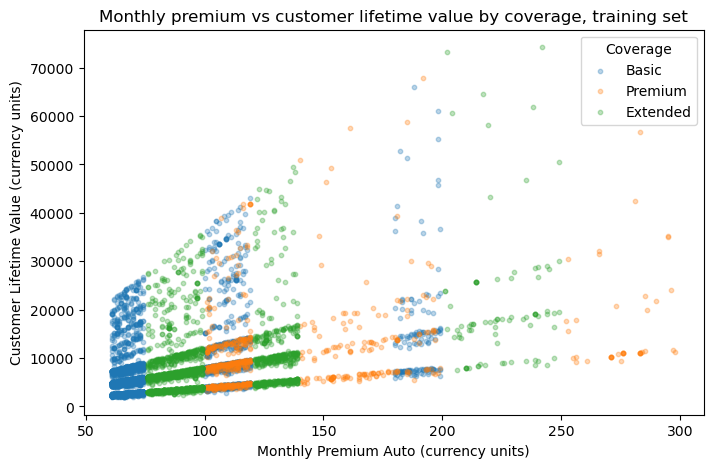


Coverage
Basic       4363
Extended    2150
Premium      663
Name: count, dtype: int64


In [105]:
plt.figure(figsize=(8, 5))

# Investigate whether distinct rays in the scatter plot correspond to policy Coverage tiers
for cat in train_df['Coverage'].unique():
    subset = train_df[train_df['Coverage'] == cat]
    plt.scatter(subset['Monthly Premium Auto'], subset[TARGET_COL], alpha=0.3, s=10, label=cat)

# Add descriptive chart labels and legend
plt.title("Monthly premium vs customer lifetime value by coverage, training set")
plt.xlabel("Monthly Premium Auto (currency units)")
plt.ylabel("Customer Lifetime Value (currency units)")
plt.legend(title="Coverage")
plt.show()

# Coverage shifts premium range (Premium > Extended > Basic) but does not isolate rays
print()
print(train_df['Coverage'].value_counts())


In [112]:
# Inspect unique values in "Policy" attribute (combines policy type and level, e.g., "Personal L3")
train_df['Policy'].value_counts()


Policy
Personal L3     2693
Personal L2     1676
Personal L1      975
Corporate L3     796
Corporate L2     446
Corporate L1     280
Special L2       136
Special L3       121
Special L1        53
Name: count, dtype: int64

In [113]:
# Feature engineering: extract policy level sub-tier ("L1", "L2", "L3") by slicing the last 2 characters
train_df["Policy Level"] = train_df["Policy"].str[-2:]


In [114]:
# Check frequency distribution across extracted Policy Levels
train_df["Policy Level"].value_counts()


Policy Level
L3    3610
L2    2258
L1    1308
Name: count, dtype: int64

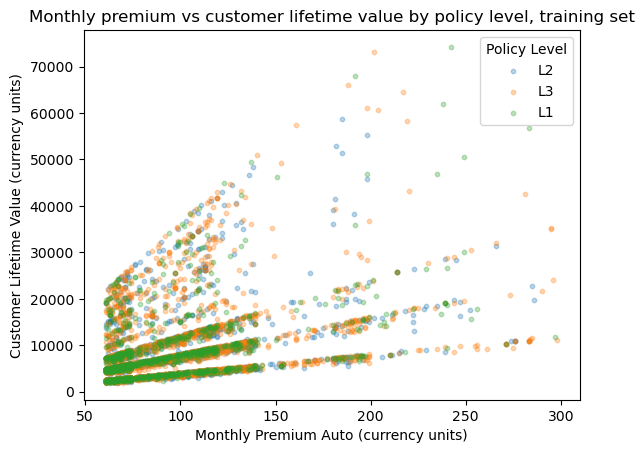

In [118]:
# Test hypothesis: Does Policy Level (L1, L2, L3) explain the distinct ray slopes?
for level in train_df['Policy Level'].unique():
    sub = train_df[train_df['Policy Level'] == level]
    plt.scatter(sub["Monthly Premium Auto"], sub[TARGET_COL], alpha=0.3, s=10, label=level)

# Add chart labels and legend
plt.title("Monthly premium vs customer lifetime value by policy level, training set")
plt.xlabel("Monthly Premium Auto (currency units)")
plt.ylabel("Customer Lifetime Value (currency units)")
plt.legend(title="Policy Level")
plt.show()
# Finding: Policy levels overlap evenly across all rays and do not explain the slope divergence


In [119]:
# Feature engineering: compute ratio of CLV to Monthly Premium Auto
# Represents the implicit lifetime multiplier (effective months of premium per policyholder)
train_df["CLV per premium"] = train_df[TARGET_COL] / train_df["Monthly Premium Auto"]


In [120]:
# Preview sample rows to inspect the newly engineered "CLV per premium" ratio
train_df.head()


,State,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size,Effective To Date (parsed),Customer Lifetime Value,Policy Level,CLV per premium
1820,California,No,Basic,High School or Below,2/23/11,Employed,F,26876,Urban,Married,66,12,53,0,2,Personal Auto,Personal L2,Offer4,Call Center,219.209762,Four-Door Car,Medsize,2011-02-23,21034.018150,L2,318.697245
737,Arizona,No,Basic,Bachelor,5/2/2011,Employed,M,83210,Suburban,Divorced,110,0,25,0,3,Personal Auto,Personal L3,Offer3,Branch,528.000000,Sports Car,Large,2011-02-05,8733.527338,L3,79.395703
4298,Washington,No,Premium,Bachelor,1/1/2011,Unemployed,F,0,Suburban,Married,281,16,92,1,2,Personal Auto,Personal L3,Offer1,Branch,1499.806352,Luxury SUV,Medsize,2011-01-01,42462.967940,L3,151.113765
2416,Arizona,No,Premium,High School or Below,9/1/2011,Unemployed,M,0,Suburban,Divorced,114,2,45,0,7,Corporate Auto,Corporate L2,Offer1,Agent,547.200000,Four-Door Car,Small,2011-01-09,8447.801005,L2,74.103518
5884,Washington,Yes,Premium,Bachelor,1/24/11,Employed,F,51643,Suburban,Single,283,16,43,0,1,Personal Auto,Personal L3,Offer2,Agent,1358.400000,Luxury Car,Medsize,2011-01-24,11009.130490,L3,38.901521


In [125]:
# Evaluate median multiplier across candidate categorical features to identify which drives the rays
# Number of Policies shows dramatic step changes (~28 for 1 policy, ~160+ for 2, ~300+ for 3+)
for cat in ["Coverage", "Policy Level", "Number of Policies", "Vehicle Class", "Renew Offer Type"]:
    print(train_df.groupby(cat)['CLV per premium'].median())
    print("-" * 50)


Coverage
Basic       76.780733
Extended    75.740576
Premium     76.054213
Name: CLV per premium, dtype: float64
--------------------------------------------------
Policy Level
L1    77.832079
L2    76.322520
L3    75.945768
Name: CLV per premium, dtype: float64
--------------------------------------------------
Number of Policies
1     39.180800
2    120.222038
3     78.620278
4     77.665019
5     78.405602
6     78.840283
7     78.360405
8     78.421119
9     78.211623
Name: CLV per premium, dtype: float64
--------------------------------------------------
Vehicle Class
Four-Door Car    76.780733
Luxury Car       72.563980
Luxury SUV       74.408931
SUV              75.957814
Sports Car       74.910621
Two-Door Car     76.696532
Name: CLV per premium, dtype: float64
--------------------------------------------------
Renew Offer Type
Offer1    77.410323
Offer2    74.761901
Offer3    77.387031
Offer4    71.297819
Name: CLV per premium, dtype: float64
----------------------------------

In [126]:
# Descriptive statistics of the multiplier ratio across the training dataset
train_df["CLV per premium"].describe()


count    7176.000000
mean       86.049469
std        64.193065
min        26.115753
25%        39.828898
50%        76.428391
75%        99.058661
max       365.815196
Name: CLV per premium, dtype: float64

In [127]:
# Discretize Number of Policies into 3 business tiers: 1 policy, 2 policies, and 3+ policies
train_df["Policies Group"] = pd.cut(
    train_df["Number of Policies"],
    bins=[0, 1, 2, 9],
    labels=["1", "2", "3+"]
)


In [129]:
# Verify class distribution across the discretized policy tiers
print(train_df["Policies Group"].value_counts())


Policies Group
3+    2806
1     2556
2     1814
Name: count, dtype: int64


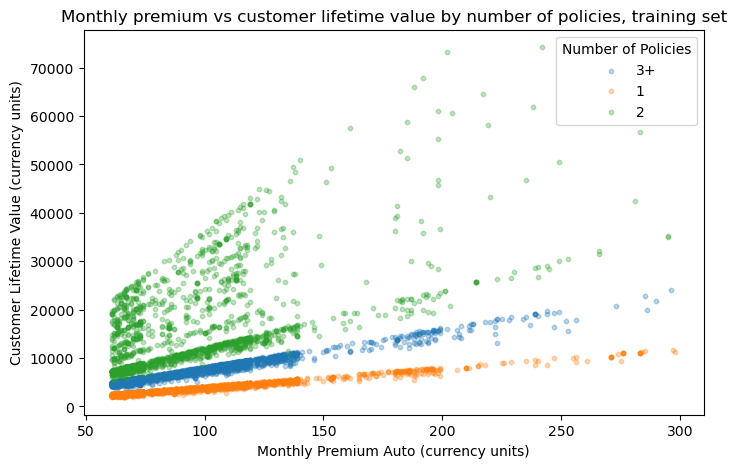

In [130]:
plt.figure(figsize=(8, 5))

# Scatter plot of Monthly Premium Auto vs CLV grouped by Number of Policies tiers
# Confirms discovery: Number of Policies definitively separates the rays/slopes
for group in train_df["Policies Group"].value_counts().index:
    sub = train_df[train_df["Policies Group"] == group]
    plt.scatter(sub["Monthly Premium Auto"], sub[TARGET_COL],
                alpha=0.3, s=10, label=group)

# Add chart titles, axis labels, and legend
plt.title("Monthly premium vs customer lifetime value by number of policies, training set")
plt.xlabel("Monthly Premium Auto (currency units)")
plt.ylabel("Customer Lifetime Value (currency units)")
plt.legend(title="Number of Policies")

plt.show()


### Correlation heatmap of numeric features

In [134]:
# Select all numeric predictor columns from X_train
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

# Construct numeric dataframe including target variable for correlation analysis
heat_df = X_train[num_cols].copy()
heat_df[TARGET_COL] = y_train

# Compute pairwise Pearson correlation matrix
corr = heat_df.corr()

# Display correlations with target variable sorted in ascending order
print(corr[TARGET_COL].sort_values())


Number of Open Complaints       -0.038228
Months Since Last Claim          0.006242
Months Since Policy Inception    0.017892
Number of Policies               0.019408
Income                           0.024584
Total Claim Amount               0.225136
Monthly Premium Auto             0.401567
Customer Lifetime Value          1.000000
Name: Customer Lifetime Value, dtype: float64


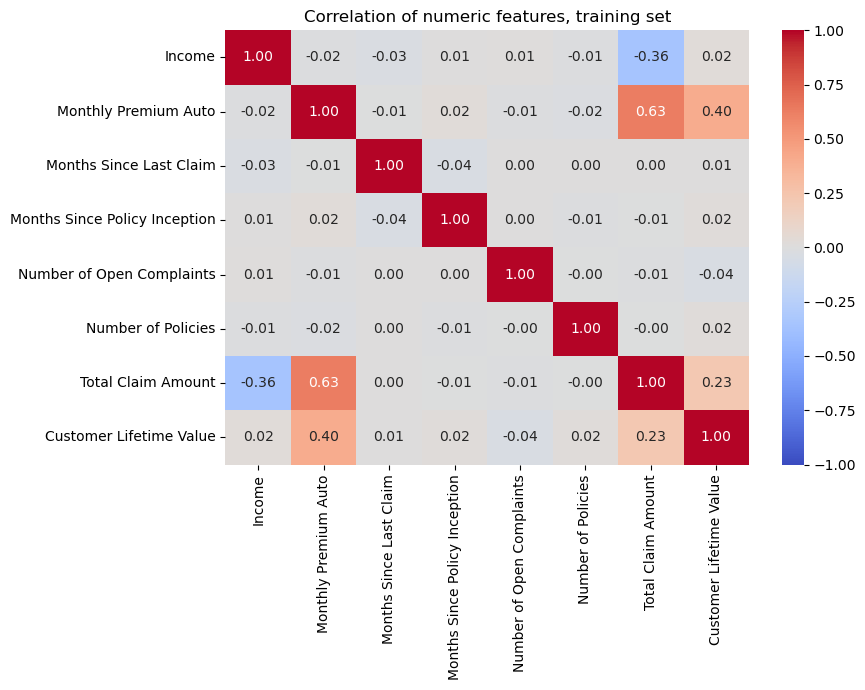

In [137]:
# Plot full numeric correlation heatmap
plt.figure(figsize=(9, 7))

# Configure diverging colormap centered at zero with annotated correlation coefficients
sns.heatmap(corr, annot=True, fmt='.2f', cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of numeric features, training set")
plt.tight_layout()
plt.show()


### Boxplots of numeric features

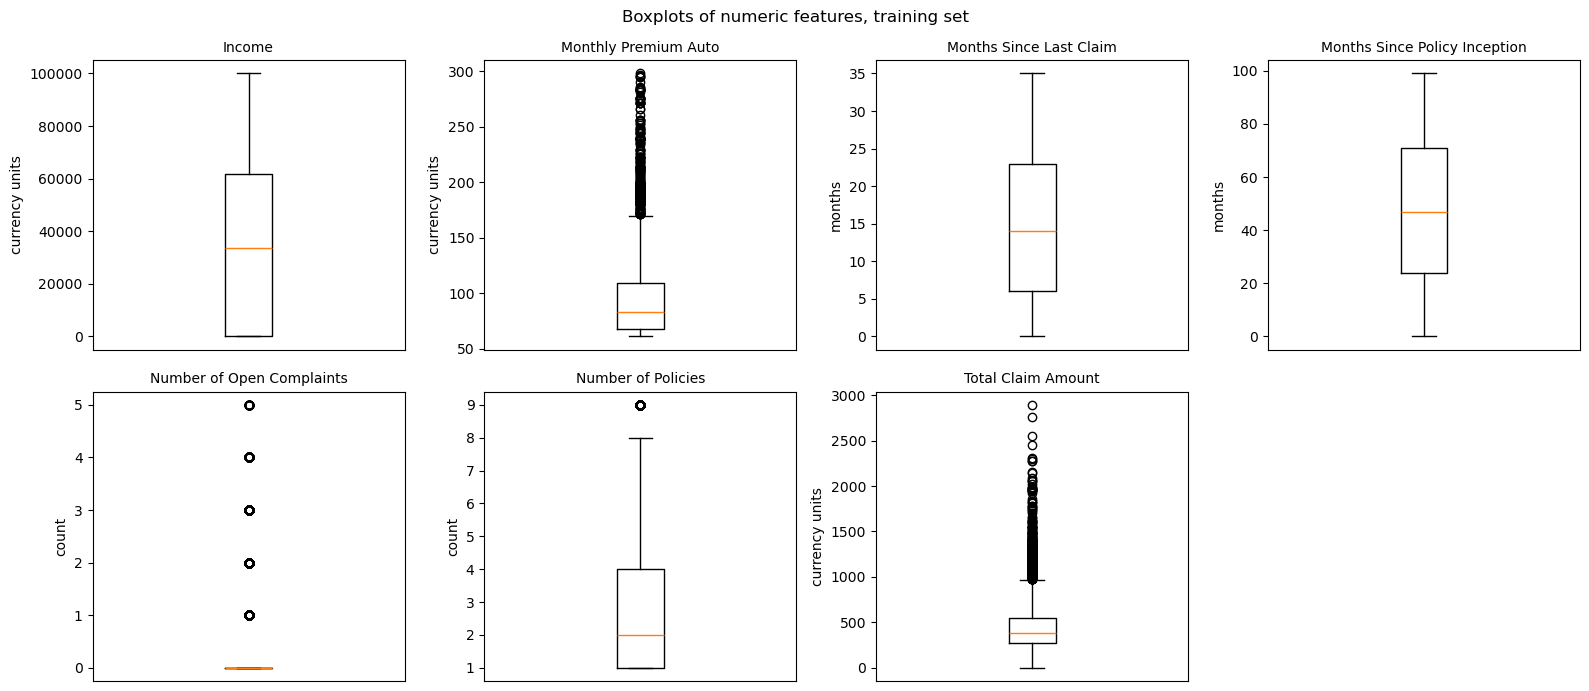

                                     min      50%           max
Income                          0.000000  33817.0  99961.000000
Monthly Premium Auto           61.000000     83.0    298.000000
Months Since Last Claim         0.000000     14.0     35.000000
Months Since Policy Inception   0.000000     47.0     99.000000
Number of Open Complaints       0.000000      0.0      5.000000
Number of Policies              1.000000      2.0      9.000000
Total Claim Amount              0.099007    384.0   2893.239678


In [139]:
# Map physical/business measurement units for clear subplot y-axis labeling
units = {
    "Income": "currency units",
    "Monthly Premium Auto": "currency units",
    "Total Claim Amount": "currency units",
    "Months Since Last Claim": "months",
    "Months Since Policy Inception": "months",
    "Number of Open Complaints": "count",
    "Number of Policies": "count",
}

# Create a 2x4 grid of subplots for the 7 numeric predictor features
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

# Generate standardized boxplots to examine distributions, quartiles, and outliers
for i, col in enumerate(num_cols):
    axes[i].boxplot(X_train[col].dropna())
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel(units.get(col, ""))
    axes[i].set_xticks([])

# Hide the unused 8th subplot in the 2x4 grid
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")

# Add overarching title and adjust layout spacing
fig.suptitle("Boxplots of numeric features, training set")
plt.tight_layout()
plt.show()

# Display min, median (50%), and max values for rapid scale and outlier inspection
print(X_train[num_cols].describe().T[["min", "50%", "max"]])


In [140]:
# 1) Skew of the three features (near 0 = symmetric, bigger = longer right tail)
print(X_train[["Monthly Premium Auto", "Total Claim Amount", "Income"]].skew())

# 2) How many customers sit in each complaints value?
print(X_train["Number of Open Complaints"].value_counts().sort_index())

# 3) Income test from before: correlation with Total Claim Amount
nz = X_train["Income"] > 0
print("All rows:", X_train["Income"].corr(X_train["Total Claim Amount"]))
print("Income > 0 only:", X_train.loc[nz, "Income"].corr(X_train.loc[nz, "Total Claim Amount"]))

Monthly Premium Auto    2.122747
Total Claim Amount      1.740734
Income                  0.291618
dtype: float64
Number of Open Complaints
0    5701
1     783
2     287
3     237
4     120
5      48
Name: count, dtype: int64
All rows: -0.3576351507850197
Income > 0 only: -0.22174379223500984


### Target by category

In [141]:
X_train.head()

,State,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,Marital Status,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size,Effective To Date (parsed)
1820,California,No,Basic,High School or Below,2/23/11,Employed,F,26876,Urban,Married,66,12,53,0,2,Personal Auto,Personal L2,Offer4,Call Center,219.209762,Four-Door Car,Medsize,2011-02-23
737,Arizona,No,Basic,Bachelor,5/2/2011,Employed,M,83210,Suburban,Divorced,110,0,25,0,3,Personal Auto,Personal L3,Offer3,Branch,528.000000,Sports Car,Large,2011-02-05
4298,Washington,No,Premium,Bachelor,1/1/2011,Unemployed,F,0,Suburban,Married,281,16,92,1,2,Personal Auto,Personal L3,Offer1,Branch,1499.806352,Luxury SUV,Medsize,2011-01-01
2416,Arizona,No,Premium,High School or Below,9/1/2011,Unemployed,M,0,Suburban,Divorced,114,2,45,0,7,Corporate Auto,Corporate L2,Offer1,Agent,547.200000,Four-Door Car,Small,2011-01-09
5884,Washington,Yes,Premium,Bachelor,1/24/11,Employed,F,51643,Suburban,Single,283,16,43,0,1,Personal Auto,Personal L3,Offer2,Agent,1358.400000,Luxury Car,Medsize,2011-01-24


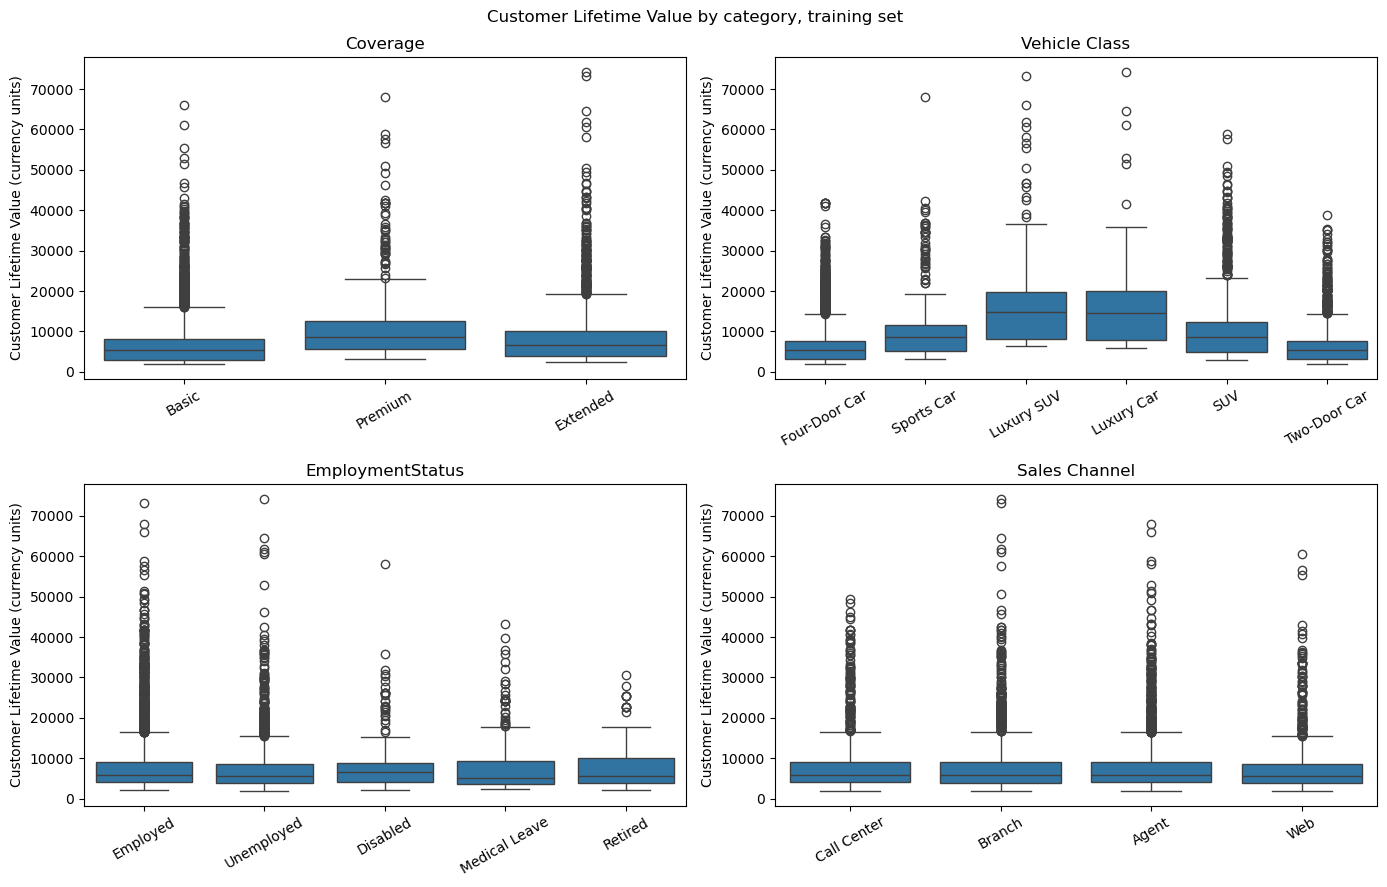

          count       median
Coverage                    
Basic      4363  5285.118669
Extended   2150  6650.636814
Premium     663  8717.777831
----------------------------------------
               count        median
Vehicle Class                     
Four-Door Car   3633   5318.896640
Luxury Car       125  14439.803130
Luxury SUV       139  14895.397980
SUV             1425   8591.305411
Sports Car       376   8564.368141
Two-Door Car    1478   5293.458141
----------------------------------------
                  count       median
EmploymentStatus                    
Disabled            317  6503.397049
Employed           4461  5876.373894
Medical Leave       334  5226.554802
Retired             210  5550.569379
Unemployed         1854  5622.938231
----------------------------------------
               count       median
Sales Channel                    
Agent           2745  5860.483090
Branch          2021  5824.767025
Call Center     1361  5802.065978
Web             1049  5

In [142]:
cat_cols = ["Coverage", "Vehicle Class", "EmploymentStatus", "Sales Channel"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    sns.boxplot(data=train_df, x=col, y=TARGET_COL, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Customer Lifetime Value (currency units)")
    axes[i].tick_params(axis="x", rotation=30)

fig.suptitle("Customer Lifetime Value by category, training set")
plt.tight_layout()
plt.show()

# rows and median target for EVERY column, not just the last one
for col in cat_cols:
    print(train_df.groupby(col)[TARGET_COL].agg(["count", "median"]))
    print("-" * 40)